# **Test Ligand Class**


In [1]:
from src.ligand import Ligand


smile = "CN1C=NC2=C1C(=O)N(C(=O)N2C)C"
sdf_path = ".\\data\\raw\\P-L\\2001-2010\\1d4h\\1d4h_ligand.sdf"
ligand_smile = Ligand.from_smile(smile)  
ligand_sdf = Ligand.from_sdf(sdf_path)

ligand_sdf.visualize_py3Dmol()
ligand_smile.visualize_py3Dmol()


c:\Users\andre\Desktop\ANDREA\POLIMI\LEONARDO\Bio_Graph_ML\GML_repo\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
[18:57:01] Warning: molecule is tagged as 2D, but at least one Z coordinate is not zero. Marking the mol as 3D.


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

[18:57:01] Molecule does not have explicit Hs. Consider calling AddHs()
[18:57:01] Molecule does not have explicit Hs. Consider calling AddHs()


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

In [2]:
x, edge_index, edge_attr, pos = ligand_smile.get_pyg_graph()


print(f"x: {x.shape}, edge_index: {edge_index.shape}, edge_attr: {edge_attr.shape}, pos: {pos.shape}")

edge_index


x: torch.Size([14, 7]), edge_index: torch.Size([2, 30]), edge_attr: torch.Size([30, 2]), pos: torch.Size([14, 3])


tensor([[ 0,  1,  1,  2,  2,  3,  3,  4,  4,  5,  5,  6,  6,  7,  6,  8,  8,  9,
          9, 10,  9, 11, 11, 12,  8, 13,  5,  1, 11,  4],
        [ 1,  0,  2,  1,  3,  2,  4,  3,  5,  4,  6,  5,  7,  6,  8,  6,  9,  8,
         10,  9, 11,  9, 12, 11, 13,  8,  1,  5,  4, 11]])

Edge Index SDF:
tensor([[ 0, 32,  1, 33,  2, 34,  3, 35,  4, 36,  5,  9,  5, 40,  6, 10,  6, 41,
          7, 22,  7, 32,  8, 33,  8, 43,  9, 37, 10, 38, 11, 14, 11, 15, 12, 16,
         12, 17, 13, 18, 13, 19, 14, 23, 15, 24, 16, 25, 17, 26, 18, 27, 19, 28,
         20, 21, 20, 29, 21, 30, 22, 39, 23, 37, 24, 37, 25, 38, 26, 38, 27, 39,
         28, 39, 29, 42, 30, 44, 31, 34, 31, 42, 32, 40, 33, 41, 34, 43, 35, 36,
         35, 40, 36, 41, 42, 44, 43, 44],
        [32,  0, 33,  1, 34,  2, 35,  3, 36,  4,  9,  5, 40,  5, 10,  6, 41,  6,
         22,  7, 32,  7, 33,  8, 43,  8, 37,  9, 38, 10, 14, 11, 15, 11, 16, 12,
         17, 12, 18, 13, 19, 13, 23, 14, 24, 15, 25, 16, 26, 17, 27, 18, 28, 19,
         21, 20, 29, 20, 30, 21, 39, 22, 37, 23, 37, 24, 38, 25, 38, 26, 39, 27,
         39, 28, 42, 29, 44, 30, 34, 31, 42, 31, 40, 32, 41, 33, 43, 34, 36, 35,
         40, 35, 41, 36, 44, 42, 44, 43]])

Edge Index SMILE:
tensor([[ 0,  1,  1,  2,  2,  3,  3,  4,  4,  5,  5,  6,  6,  7,  7,  

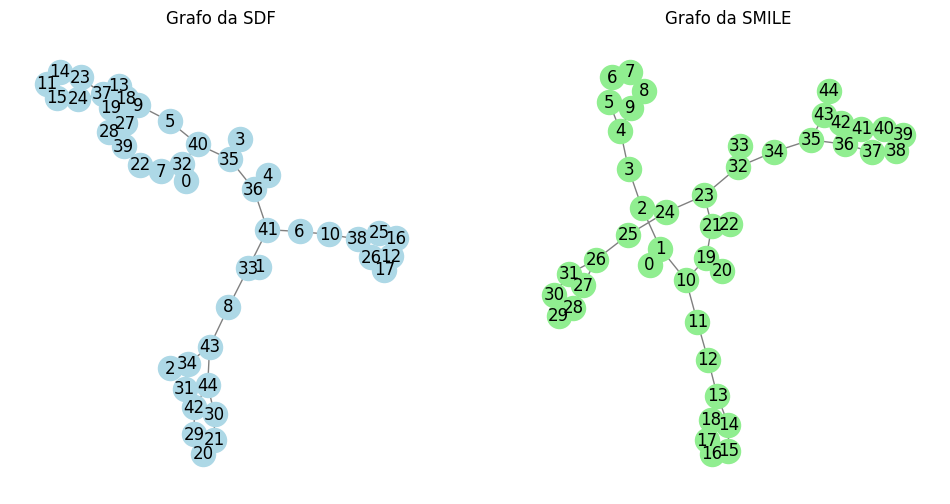

In [3]:
import networkx as nx
import matplotlib.pyplot as plt

ligand_sdf_smile = Ligand.from_smile(ligand_sdf.to_smile())

edge_index_sdf = ligand_sdf._get_edge_index()
edge_index_smile = ligand_sdf_smile._get_edge_index()

print("Edge Index SDF:")
print(edge_index_sdf)   
print("\nEdge Index SMILE:")
print(edge_index_smile)

#costruisco due grafi nx dagli edge_index sono in formato COO, devo convertirli in formato adiacenza
def edge_index_to_nx(edge_index):
    G = nx.Graph()
    for i in range(edge_index.shape[1]):
        G.add_edge(edge_index[0, i].item(), edge_index[1, i].item())
    return G

G_sdf = edge_index_to_nx(edge_index_sdf)
G_smile = edge_index_to_nx(edge_index_smile)

#plotto i grafi e verifico che siano isomorfi

plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
nx.draw(G_sdf, with_labels=True, node_color='lightblue', edge_color='gray')
plt.title("Grafo da SDF")
plt.subplot(1, 2, 2)
nx.draw(G_smile, with_labels=True, node_color='lightgreen', edge_color='gray')
plt.title("Grafo da SMILE")
plt.show()


In [4]:
from networkx.algorithms import isomorphism

# Verifica semplice isomorfismo
are_isomorphic = nx.is_isomorphic(G_sdf, G_smile)

print(f"I due grafi sono isomorfi? {are_isomorphic}")

if are_isomorphic:
    NM = isomorphism.GraphMatcher(G_sdf, G_smile)
    if NM.is_isomorphic():
        print("Mappa di corrispondenza atomi (SDF -> SMILE):")
        print(NM.mapping)

I due grafi sono isomorfi? True
Mappa di corrispondenza atomi (SDF -> SMILE):
{0: 0, 32: 1, 7: 2, 22: 3, 39: 4, 27: 5, 18: 6, 13: 7, 19: 8, 28: 9, 40: 10, 5: 11, 9: 12, 37: 13, 24: 14, 15: 15, 11: 16, 14: 17, 23: 18, 35: 19, 3: 20, 36: 21, 4: 22, 41: 23, 6: 24, 10: 25, 38: 26, 26: 27, 17: 28, 12: 29, 16: 30, 25: 31, 33: 32, 1: 33, 8: 34, 43: 35, 44: 36, 30: 37, 21: 38, 20: 39, 29: 40, 42: 41, 31: 42, 34: 43, 2: 44}


## Verifica correttezza features

In [6]:
# verifico che le feature degli atomi
print(f"x.shape: {x.shape} - numero di atomi: {x.shape[0]}, numero di feature per atomo: {x.shape[1]}")
print("x [numero_atomico, grado, H_totali, carica_formale, aromaticità, anello, ibridazione]:")
x_smile = ligand_smile._get_node_features()
print(x_smile)

mol=ligand_smile.mol
for atom in mol.GetAtoms():
    print(f"Atomo {atom.GetIdx()}: {atom.GetSymbol()}, grado: {atom.GetDegree()}, H_totali: {atom.GetTotalNumHs()}, carica formale: {atom.GetFormalCharge()}, aromaticità: {atom.GetIsAromatic()}, anello: {atom.IsInRing()}, ibridazione: {atom.GetHybridization()}")

x.shape: torch.Size([14, 7]) - numero di atomi: 14, numero di feature per atomo: 7
x [numero_atomico, grado, H_totali, carica_formale, aromaticità, anello, ibridazione]:
tensor([[6., 1., 3., 0., 0., 0., 3.],
        [7., 3., 0., 0., 1., 1., 2.],
        [6., 2., 1., 0., 1., 1., 2.],
        [7., 2., 0., 0., 1., 1., 2.],
        [6., 3., 0., 0., 1., 1., 2.],
        [6., 3., 0., 0., 1., 1., 2.],
        [6., 3., 0., 0., 0., 1., 2.],
        [8., 1., 0., 0., 0., 0., 2.],
        [7., 3., 0., 0., 0., 1., 2.],
        [6., 3., 0., 0., 0., 1., 2.],
        [8., 1., 0., 0., 0., 0., 2.],
        [7., 3., 0., 0., 0., 1., 2.],
        [6., 1., 3., 0., 0., 0., 3.],
        [6., 1., 3., 0., 0., 0., 3.]])
Atomo 0: C, grado: 1, H_totali: 3, carica formale: 0, aromaticità: False, anello: False, ibridazione: SP3
Atomo 1: N, grado: 3, H_totali: 0, carica formale: 0, aromaticità: True, anello: True, ibridazione: SP2
Atomo 2: C, grado: 2, H_totali: 1, carica formale: 0, aromaticità: True, anello: True, 